# 02 – Detekcia bot účtov (Cresci-17)

Tri experimenty na rovnakých dátach a rovnakom rozdelení:

1. **Metadáta**: údaje o účte (followers, following, počet tweetov, vek účtu...)
2. **Text**: TF-IDF z tweetov + Logistic Regression
3. **Metadáta + text**: jeden spoločný model (TF-IDF a zoškálované metadáta v jednej tabuľke)

Transformer (DistilBERT) sa pridá ako ďalší experiment do tohto notebooku neskôr.

Pravidlá, ktoré dodržiavame:
- jeden riadok = jeden účet, takže rozdelenie train/val/test je **po účtoch** (tweety jedného účtu nikdy nie sú v dvoch splitoch),
- do modelov ide len vopred zvolený zoznam príznakov (nie `test_set_*`, `source`, `crawled_at`...),
- do textového modelu ide len `tweets_text`, nie `text` (ten obsahuje aj `screen_name`).

## 1. Import a cesty

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root():
    """Koreň repozitára (priečinok s .git); ak nie je, aktuálny priečinok."""
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / ".git").exists():
            return d
    return p.parent if p.name == "notebooks" else p


def find_processed_dir(root):
    """Nájde data/processed v koreni alebo v src/ (podľa toho, kde ho máš)."""
    for base in [root, root / "src"]:
        d = base / "data" / "processed"
        if d.exists():
            return d
    raise FileNotFoundError("Nenašiel som data/processed ani v koreni, ani v src/.")


PROJECT_DIR = find_project_root()
DATA_DIR = find_processed_dir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))

from evaluation import compute_metrics, save_results, plot_confusion

DATA_FILE = DATA_DIR / "cresci_prepared.csv"
SPLIT_FILE = DATA_DIR / "bots_splits.csv"
RESULTS_FILE = PROJECT_DIR / "results" / "bot_results.csv"
FIG_DIR = PROJECT_DIR / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
print("Projektový priečinok:", PROJECT_DIR)

Projektový priečinok: /Users/juraj/Documents/GitHub/bakalarska_praca


## 2. Načítanie a rozdelenie train / val / test (70 / 15 / 15)

Rozdelenie sa vytvorí raz, uloží do `bots_splits.csv` a potom sa pre všetky experimenty (aj transformer) používa to isté. Ak niekedy zmeníš `cresci_prepared.csv` (iné účty), zmaž `bots_splits.csv`, nech sa vytvorí nové.

In [2]:
from sklearn.model_selection import train_test_split

bots = pd.read_csv(DATA_FILE, low_memory=False)
bots["tweets_text"] = bots["tweets_text"].fillna("").astype(str)
assert bots["user_id"].is_unique, "user_id sa opakuje, skontroluj prepare_cresci.py"
bots["user_id"] = bots["user_id"].astype(str)

if SPLIT_FILE.exists():
    splits = pd.read_csv(SPLIT_FILE, dtype={"user_id": str})
    bots = bots.merge(splits, on="user_id", how="left")
    assert bots["split"].notna().all(), "bots_splits.csv nesedí s dátami, zmaž ho a spusti znova"
    print("Rozdelenie načítané zo súboru.")
else:
    idx_train, idx_tmp = train_test_split(
        bots.index, test_size=0.30, stratify=bots["label"], random_state=RANDOM_STATE)
    idx_val, idx_test = train_test_split(
        idx_tmp, test_size=0.50, stratify=bots.loc[idx_tmp, "label"], random_state=RANDOM_STATE)
    bots["split"] = "train"
    bots.loc[idx_val, "split"] = "val"
    bots.loc[idx_test, "split"] = "test"
    bots[["user_id", "split"]].to_csv(SPLIT_FILE, index=False)
    print("Nové rozdelenie vytvorené a uložené.")

display(bots.groupby(["split", "label_name"]).size().unstack())

Nové rozdelenie vytvorené a uložené.


label_name,bot,human
split,,
test,149,163
train,693,758
val,149,162


## 3. Príznaky z metadát

Základ: počty z profilu. Odvodené príznaky:
- `account_age_days`: vek účtu k **jednému pevnému dátumu pre všetkých** (najnovší `created_at` v dátach), aby rozdiel nezáležal od toho, kedy bola ktorá skupina stiahnutá,
- `followers_friends_ratio`: followers / (following + 1),
- `statuses_per_day`: tweety za deň existencie účtu,
- `has_description`: či má účet vyplnený popis.

In [3]:
try:
    created = pd.to_datetime(bots["created_at"], errors="coerce", utc=True, format="mixed")
except (TypeError, ValueError):
    created = pd.to_datetime(bots["created_at"], errors="coerce", utc=True)

print("created_at sa nepodarilo prečítať u:", created.isna().sum(), "účtov")
ref_date = created.max()
print("Referenčný dátum:", ref_date)

bots["account_age_days"] = (ref_date - created).dt.days.clip(lower=0)
bots["followers_friends_ratio"] = bots["followers_count"] / (bots["friends_count"] + 1)
bots["statuses_per_day"] = bots["statuses_count"] / (bots["account_age_days"] + 1)
bots["has_description"] = (bots["description"].fillna("").astype(str).str.strip() != "").astype(int)

META_FEATURES = [
    "statuses_count", "followers_count", "friends_count", "favourites_count", "listed_count",
    "account_age_days", "followers_friends_ratio", "statuses_per_day", "has_description",
]

train = bots[bots["split"] == "train"]
val = bots[bots["split"] == "val"]
test = bots[bots["split"] == "test"]
y_train, y_val, y_test = train["label"], val["label"], test["label"]

display(bots.groupby("label_name")[META_FEATURES].median().T.round(2))

created_at sa nepodarilo prečítať u: 0 účtov
Referenčný dátum: 2014-05-26 15:32:52+00:00


label_name,bot,human
statuses_count,138.00,8272.00
followers_count,234.00,407.00
friends_count,313.00,366.00
favourites_count,0.00,1492.00
listed_count,0.00,3.00
account_age_days,859.00,841.00
followers_friends_ratio,0.80,1.04
statuses_per_day,0.16,10.75
has_description,1.00,1.00


## 4. Pomocné funkcie a modely

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


def make_meta_preprocessor():
    """Doplnenie chýbajúcich hodnôt, log1p (počty majú extrémne hodnoty) a škálovanie."""
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
    ])


def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)


def make_lr():
    return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)


all_rows = []   # metriky všetkých experimentov
store = {}      # natrénované modely a predikcie


def run_experiment(name, model, cols):
    """Natrénuje model na train a vyhodnotí ho na val a test."""
    model.fit(train[cols], y_train)
    preds = {}
    for split_name, df, y_true in [("val", val, y_val), ("test", test, y_test)]:
        y_pred = model.predict(df[cols])
        preds[split_name] = y_pred
        all_rows.append({"experiment": name, "split": split_name, **compute_metrics(y_true, y_pred)})
    store[name] = (model, preds)
    display(pd.DataFrame([r for r in all_rows if r["experiment"] == name]))

## 5. Experiment 1 – Metadáta

,experiment,split,accuracy,precision,recall,f1
0,1a Metadáta – Logistic Regression,val,0.9743,0.9732,0.9732,0.9732
1,1a Metadáta – Logistic Regression,test,0.9712,0.9795,0.9597,0.9695


,experiment,split,accuracy,precision,recall,f1
0,1b Metadáta – Random Forest,val,0.9839,0.9932,0.9732,0.9831
1,1b Metadáta – Random Forest,test,0.9744,0.9930,0.9530,0.9726


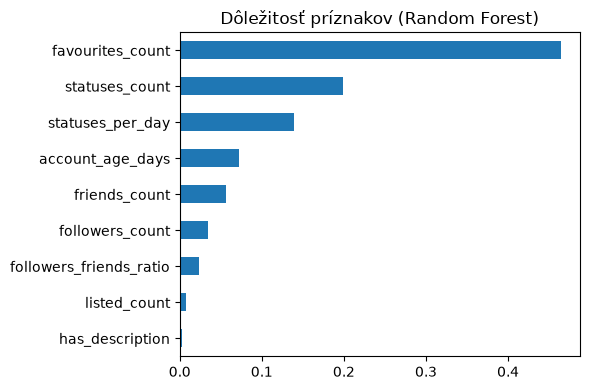

In [5]:
run_experiment(
    "1a Metadáta – Logistic Regression",
    Pipeline([("prep", make_meta_preprocessor()), ("clf", make_lr())]),
    META_FEATURES,
)
run_experiment(
    "1b Metadáta – Random Forest",
    Pipeline([("impute", SimpleImputer(strategy="median")),
              ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                             random_state=RANDOM_STATE, n_jobs=-1))]),
    META_FEATURES,
)

rf = store["1b Metadáta – Random Forest"][0].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=META_FEATURES).sort_values()
imp.plot.barh(figsize=(6, 4), title="Dôležitosť príznakov (Random Forest)")
plt.tight_layout(); plt.savefig(FIG_DIR / "bot_meta_importance.png", dpi=150); plt.show()

## Podiel uctov s hodnotou favourites_count = 0

In [9]:
display(bots.groupby("label_name")["favourites_count"].describe().round(1))
print("Podiel účtov s favourites_count == 0:")
print((bots["favourites_count"] == 0).groupby(bots["label_name"]).mean().round(3))

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
bot,991.0,158.2,2160.9,0.0,0.0,0.0,0.0,50699.0
human,1083.0,4676.1,10223.2,0.0,295.5,1492.0,4937.0,185467.0


Podiel účtov s favourites_count == 0:
label_name
bot      0.915
human    0.009
Name: favourites_count, dtype: float64


## Ablacna studia bez favourites_count

In [10]:
no_fav = [f for f in META_FEATURES if f != "favourites_count"]
no_top3 = [f for f in META_FEATURES
           if f not in ("favourites_count", "statuses_count", "statuses_per_day")]

for name, cols in [("1c Metadáta bez favourites – RF", no_fav),
                   ("1d Metadáta bez top 3 – RF", no_top3)]:
    run_experiment(
        name,
        Pipeline([("impute", SimpleImputer(strategy="median")),
                  ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                 random_state=RANDOM_STATE, n_jobs=-1))]),
        cols,
    )

,experiment,split,accuracy,precision,recall,f1
0,1c Metadáta bez favourites – RF,val,0.9678,0.9664,0.9664,0.9664
1,1c Metadáta bez favourites – RF,test,0.9679,0.9793,0.9530,0.9660


,experiment,split,accuracy,precision,recall,f1
0,1d Metadáta bez top 3 – RF,val,0.9582,0.9595,0.9530,0.9562
1,1d Metadáta bez top 3 – RF,test,0.9615,0.9724,0.9463,0.9592


## Permutacna dolezitost

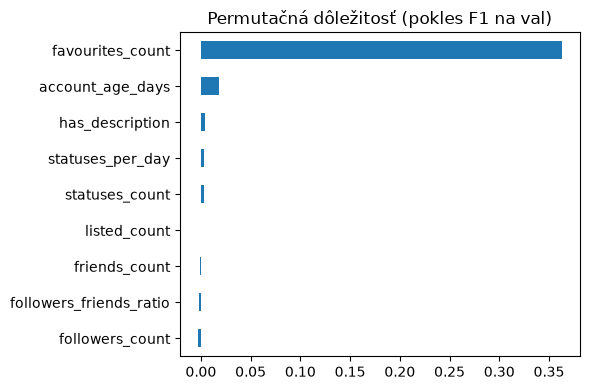

In [11]:
from sklearn.inspection import permutation_importance

rf_model = store["1b Metadáta – Random Forest"][0]
pi = permutation_importance(rf_model, val[META_FEATURES], y_val,
                            scoring="f1", n_repeats=10, random_state=RANDOM_STATE)
pd.Series(pi.importances_mean, index=META_FEATURES).sort_values().plot.barh(
    figsize=(6, 4), title="Permutačná dôležitosť (pokles F1 na val)")
plt.tight_layout(); plt.savefig(FIG_DIR / "bot_meta_permutation.png", dpi=150); plt.show()

## 6. Experiment 2 – Text (TF-IDF + Logistic Regression)

In [6]:
run_experiment(
    "2 Text – TF-IDF + LR",
    Pipeline([("tfidf", make_tfidf()), ("clf", make_lr())]),
    "tweets_text",
)

text_model = store["2 Text – TF-IDF + LR"][0]
words = text_model.named_steps["tfidf"].get_feature_names_out()
coef = text_model.named_steps["clf"].coef_[0]
order = np.argsort(coef)
print("Slová typické pre BOTA:  ", ", ".join(words[order[-20:]][::-1]))
print("Slová typické pre ČLOVEKA:", ", ".join(words[order[:20]]))

,experiment,split,accuracy,precision,recall,f1
0,2 Text – TF-IDF + LR,val,1.0000,1.0,1.0000,1.0000
1,2 Text – TF-IDF + LR,test,0.9968,1.0,0.9933,0.9966


Slová typické pre BOTA:   che, di, non, il, la, un, per, le, io, una, ma, sono, se, si, ti, mi, da, ho, con, amo
Slová typické pre ČLOVEKA: rt, the, to, you, and, co, is, of, http, it, http co, for, https, https co, my, this, on, that, at, be


## 7. Experiment 3 – Metadáta + text v jednom modeli

TF-IDF príznaky z tweetov a zoškálované metadáta sa dajú vedľa seba do jednej tabuľky (`ColumnTransformer`) a natrénuje sa **jeden** model.

In [7]:
combined_prep = ColumnTransformer([
    ("text", make_tfidf(), "tweets_text"),
    ("meta", make_meta_preprocessor(), META_FEATURES),
])

run_experiment(
    "3 Metadáta + text – LR",
    Pipeline([("prep", combined_prep), ("clf", make_lr())]),
    ["tweets_text"] + META_FEATURES,
)

,experiment,split,accuracy,precision,recall,f1
0,3 Metadáta + text – LR,val,0.9871,0.9932,0.9799,0.9865
1,3 Metadáta + text – LR,test,0.9904,1.0000,0.9799,0.9898


## 8. Porovnanie a uloženie výsledkov

Výber najlepšieho modelu robíme podľa **F1 na val**, výsledok hlásime na **test**.

Pozor: ak je niekde výsledok 1.00 alebo veľmi blízko, nie je to automaticky úspech. Dataset obsahuje len jeden typ botov (`social_spambots_1`), ktorý je veľmi uniformný, takže jednoduché modely ho môžu rozpoznať takmer dokonale. Ak sa to stane, napíš to do zápisníka ako zistenie a obmedzenie.

Uložené do: /Users/juraj/Documents/GitHub/bakalarska_praca/results/bot_results.csv


,accuracy,precision,recall,f1
experiment,,,,
1a Metadáta – Logistic Regression,0.9743,0.9732,0.9732,0.9732
1b Metadáta – Random Forest,0.9839,0.9932,0.9732,0.9831
2 Text – TF-IDF + LR,1.0000,1.0000,1.0000,1.0000
3 Metadáta + text – LR,0.9871,0.9932,0.9799,0.9865


,accuracy,precision,recall,f1
experiment,,,,
2 Text – TF-IDF + LR,0.9968,1.0000,0.9933,0.9966
3 Metadáta + text – LR,0.9904,1.0000,0.9799,0.9898
1b Metadáta – Random Forest,0.9744,0.9930,0.9530,0.9726
1a Metadáta – Logistic Regression,0.9712,0.9795,0.9597,0.9695


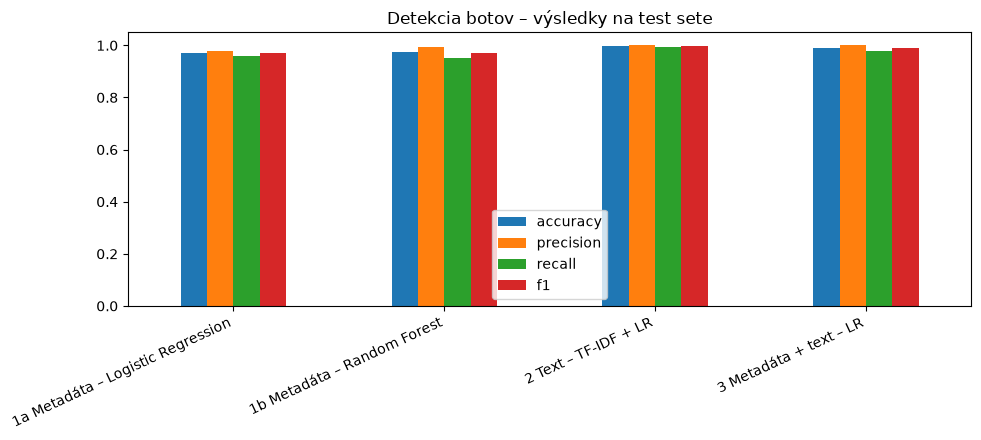

Najlepší model podľa val F1: 2 Text – TF-IDF + LR


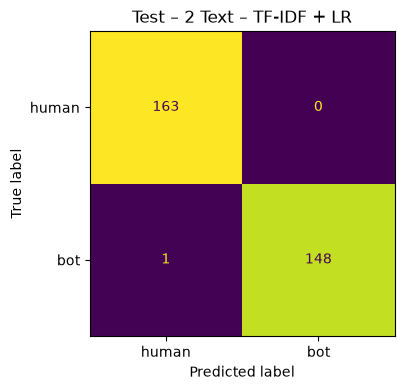

In [8]:
results = save_results(RESULTS_FILE, all_rows)
print("Uložené do:", RESULTS_FILE)

res = pd.DataFrame(all_rows)
display(res[res["split"] == "val"].set_index("experiment").drop(columns="split"))
test_table = res[res["split"] == "test"].set_index("experiment").drop(columns="split")
display(test_table.sort_values("f1", ascending=False))

ax = test_table[["accuracy", "precision", "recall", "f1"]].plot.bar(figsize=(10, 4.5))
ax.set_title("Detekcia botov – výsledky na test sete")
ax.set_ylim(0, 1.05); ax.set_xlabel("")
plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.savefig(FIG_DIR / "bot_results_comparison.png", dpi=150); plt.show()

best = res[res["split"] == "val"].sort_values("f1", ascending=False).iloc[0]["experiment"]
print("Najlepší model podľa val F1:", best)
plot_confusion(y_test, store[best][1]["test"], f"Test – {best}",
               save_path=FIG_DIR / "bot_best_confusion.png")

## 9. Čo zapísať do zápisníka

- tabuľku výsledkov (zo súboru `results/bot_results.csv`),
- ktorý prístup vyšiel najlepšie a o koľko,
- ktoré príznaky/slová boli najdôležitejšie,
- či je niektorý výsledok podozrivo dokonalý a prečo (jeden typ botov, uniformné tweety),
- čo ďalej: transformer (DistilBERT) na `tweets_text`, potom rovnaký postup pre AI detekciu.